<a href="https://colab.research.google.com/github/tahzibultamim/PythonProjects/blob/sM/knn%2Clogistic_reg%2Cconfusion_metrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Mount Google Drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
# Update the filename if your CSV is named differently inside datasets/
FILE_PATH = '/content/drive/MyDrive/datasets/cybersecurity_intrusion_data.csv'

df = pd.read_csv(FILE_PATH)

# Automatically detect target column (defaults to 'attack_detected' or last column)
TARGET_COL = 'attack_detected' if 'attack_detected' in df.columns else df.columns[-1]

print("=== 1. DATASET SHAPE ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("=== 2. FIRST 5 ROWS ===")
display(df.head())

print("\n=== 3. MISSING VALUES PER COLUMN ===")
print(df.isnull().sum())

print(f"\n=== 4. CLASS DISTRIBUTION ({TARGET_COL}) ===")
class_counts = df[TARGET_COL].value_counts()
class_pct = df[TARGET_COL].value_counts(normalize=True) * 100
dist_df = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_pct.round(2)})
display(dist_df)


=== 1. DATASET SHAPE ===
Rows: 9537, Columns: 11

=== 2. FIRST 5 ROWS ===


,session_id,network_packet_size,protocol_type,login_attempts,session_duration,encryption_used,ip_reputation_score,failed_logins,browser_type,unusual_time_access,attack_detected
0,SID_00001,599,TCP,4,492.983263,DES,0.606818,1,Edge,0,1
1,SID_00002,472,TCP,3,1557.996461,DES,0.301569,0,Firefox,0,0
2,SID_00003,629,TCP,3,75.044262,DES,0.739164,2,Chrome,0,1
3,SID_00004,804,UDP,4,601.248835,DES,0.123267,0,Unknown,0,1
4,SID_00005,453,TCP,5,532.540888,AES,0.054874,1,Firefox,0,0



=== 3. MISSING VALUES PER COLUMN ===
session_id                0
network_packet_size       0
protocol_type             0
login_attempts            0
session_duration          0
encryption_used        1966
ip_reputation_score       0
failed_logins             0
browser_type              0
unusual_time_access       0
attack_detected           0
dtype: int64

=== 4. CLASS DISTRIBUTION (attack_detected) ===


,Count,Percentage (%)
attack_detected,,
0,5273,55.29
1,4264,44.71


In [4]:
df_clean = df.copy()

# 1. Drop irrelevant identifier columns (e.g., 'session_id', 'id', 'Unnamed: 0')
id_cols = [col for col in df_clean.columns if col.lower() in ['session_id', 'id', 'unnamed: 0']]
if id_cols:
    df_clean.drop(columns=id_cols, inplace=True)
    print(f"Dropped irrelevant columns: {id_cols}")

# 2. Convert categorical feature columns to numeric codes (preserving NaN for median imputation)
cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns.tolist()
if TARGET_COL in cat_cols:
    cat_cols.remove(TARGET_COL)
    df_clean[TARGET_COL] = df_clean[TARGET_COL].astype('category').cat.codes

for col in cat_cols:
    df_clean[col] = df_clean[col].astype('category').cat.codes.replace(-1, np.nan)

# 3. Fill missing values with median
df_clean.fillna(df_clean.median(numeric_only=True), inplace=True)
print(f"Remaining missing values after median imputation: {df_clean.isnull().sum().sum()}")

# 4. Separate features (X) and target (y)
X = df_clean.drop(columns=[TARGET_COL])
y = df_clean[TARGET_COL]

# 5. Train-test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 6. Scale features using StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape:  {X_test_scaled.shape}")


Dropped irrelevant columns: ['session_id']
Remaining missing values after median imputation: 0
Training set shape: (7629, 9)
Testing set shape:  (1908, 9)


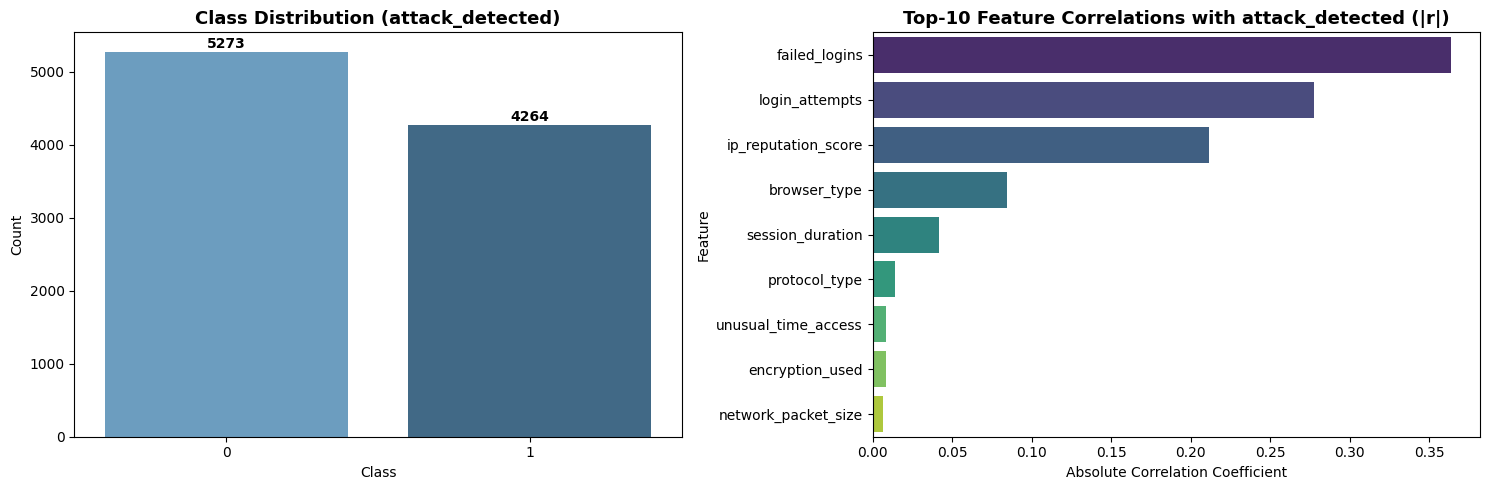

=== TOP-10 FEATURE CORRELATIONS ===


,Abs_Correlation
failed_logins,0.363726
login_attempts,0.277320
ip_reputation_score,0.211540
browser_type,0.084167
session_duration,0.041602
protocol_type,0.013890
unusual_time_access,0.008652
encryption_used,0.008306
network_packet_size,0.006798


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Bar chart of class distribution
class_counts = df_clean[TARGET_COL].value_counts().sort_index()
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, ax=axes[0], palette='Blues_d')
axes[0].set_title(f'Class Distribution ({TARGET_COL})', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Count')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + (max(class_counts.values) * 0.01), str(v), ha='center', fontweight='bold')

# 2. Top-10 feature correlations with the target
corr_with_target = (
    df_clean.corr(numeric_only=True)[TARGET_COL]
    .drop(TARGET_COL)
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

sns.barplot(x=corr_with_target.values, y=corr_with_target.index, ax=axes[1], palette='viridis')
axes[1].set_title(f'Top-10 Feature Correlations with {TARGET_COL} (|r|)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Absolute Correlation Coefficient')
axes[1].set_ylabel('Feature')

plt.tight_layout()
plt.show()

print("=== TOP-10 FEATURE CORRELATIONS ===")
display(corr_with_target.to_frame(name='Abs_Correlation'))


In [6]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42)
}

avg_method = 'binary' if y.nunique() == 2 else 'weighted'
model_results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred

    model_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average=avg_method, zero_division=0),
        'Recall': recall_score(y_test, y_pred, average=avg_method, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, average=avg_method, zero_division=0)
    })

results_df = pd.DataFrame(model_results)
print("=== MODEL PERFORMANCE SUMMARY ===")
display(results_df.round(4))


=== MODEL PERFORMANCE SUMMARY ===


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.8129,0.7884,0.7948,0.7916
1,KNN (k=5),0.8071,0.8748,0.6635,0.7547
2,Logistic Regression,0.7227,0.7066,0.6495,0.6768


=== DECISION TREE DEPTH TUNING TABLE ===


,max_depth,Accuracy,Precision,Recall,F1-Score
0,3,0.8643,1.0000,0.6964,0.8210
1,5,0.8842,1.0000,0.7409,0.8512
2,10,0.8810,0.9830,0.7468,0.8488
3,15,0.8700,0.9403,0.7573,0.8390
4,20,0.8480,0.8680,0.7784,0.8208
5,None,0.8129,0.7884,0.7948,0.7916


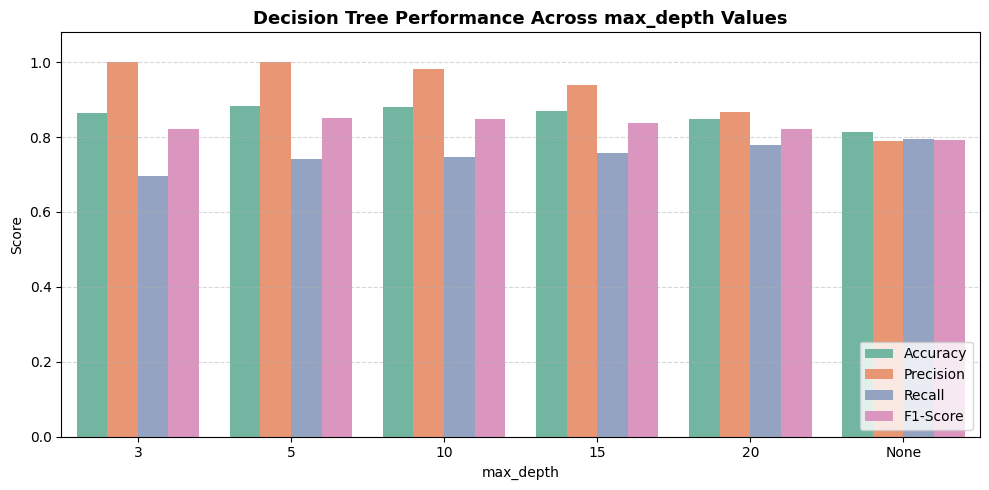

In [7]:
depths = [3, 5, 10, 15, 20, None]
depth_results = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=42)
    dt.fit(X_train_scaled, y_train)
    y_pred_dt = dt.predict(X_test_scaled)

    depth_results.append({
        'max_depth': str(d),
        'Accuracy': accuracy_score(y_test, y_pred_dt),
        'Precision': precision_score(y_test, y_pred_dt, average=avg_method, zero_division=0),
        'Recall': recall_score(y_test, y_pred_dt, average=avg_method, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred_dt, average=avg_method, zero_division=0)
    })

depth_df = pd.DataFrame(depth_results)
print("=== DECISION TREE DEPTH TUNING TABLE ===")
display(depth_df.round(4))

# Bar chart of Decision Tree depth tuning
depth_melted = depth_df.melt(id_vars='max_depth', var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 5))
sns.barplot(data=depth_melted, x='max_depth', y='Score', hue='Metric', palette='Set2')
plt.title('Decision Tree Performance Across max_depth Values', fontsize=13, fontweight='bold')
plt.xlabel('max_depth')
plt.ylabel('Score')
plt.ylim(0, 1.08)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


=== CLASSIFICATION REPORTS ===

--- Decision Tree ---
              precision    recall  f1-score   support

           0     0.8330    0.8275    0.8302      1055
           1     0.7884    0.7948    0.7916       853

    accuracy                         0.8129      1908
   macro avg     0.8107    0.8112    0.8109      1908
weighted avg     0.8131    0.8129    0.8130      1908

--- KNN (k=5) ---
              precision    recall  f1-score   support

           0     0.7724    0.9232    0.8411      1055
           1     0.8748    0.6635    0.7547       853

    accuracy                         0.8071      1908
   macro avg     0.8236    0.7934    0.7979      1908
weighted avg     0.8182    0.8071    0.8025      1908

--- Logistic Regression ---
              precision    recall  f1-score   support

           0     0.7340    0.7820    0.7572      1055
           1     0.7066    0.6495    0.6768       853

    accuracy                         0.7227      1908
   macro avg     0.7203    0

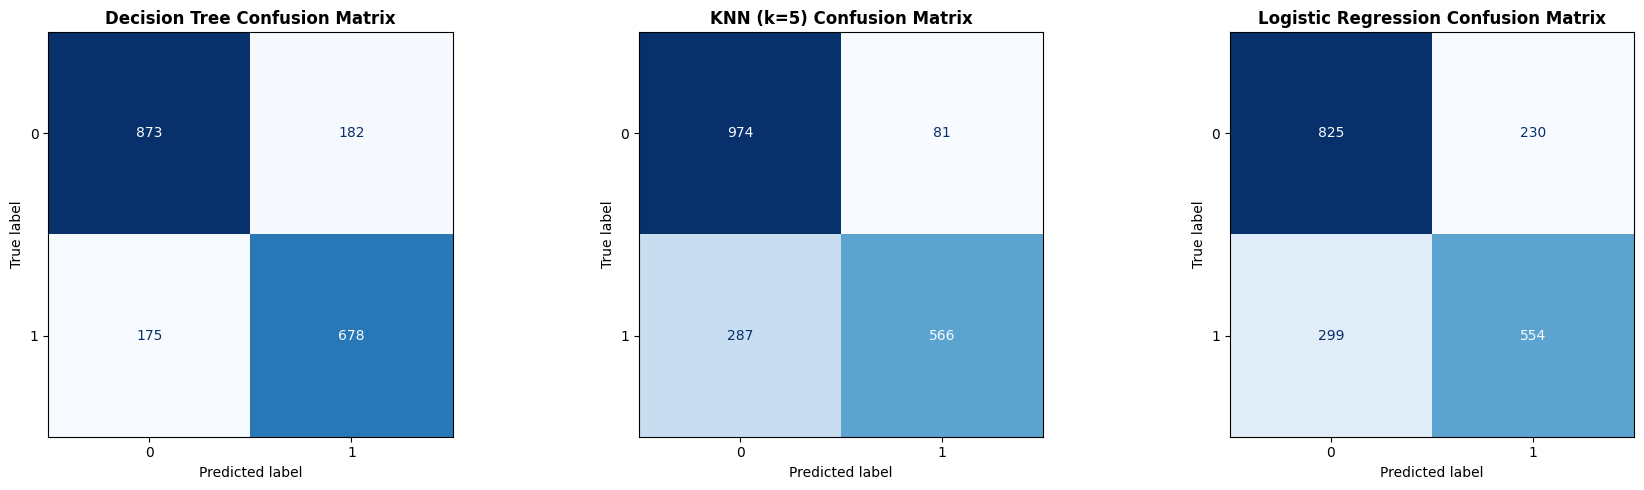

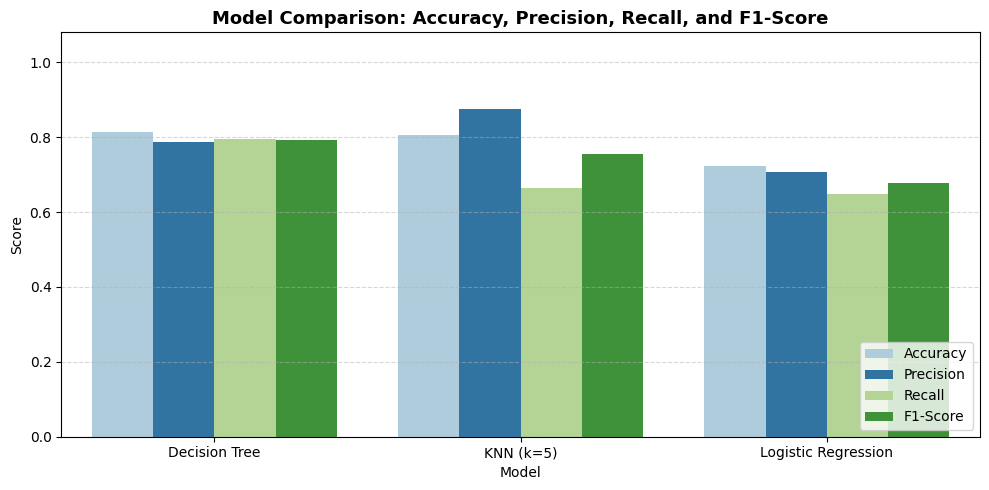

In [8]:
# 1. Classification Reports
print("=== CLASSIFICATION REPORTS ===\n")
for name, y_pred in predictions.items():
    print(f"--- {name} ---")
    print(classification_report(y_test, y_pred, digits=4))

# 2. 1x3 Confusion Matrix Grid
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name} Confusion Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# 3. Model Comparison Bar Chart
results_melted = results_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(10, 5))
sns.barplot(data=results_melted, x='Model', y='Score', hue='Metric', palette='Paired')
plt.title('Model Comparison: Accuracy, Precision, Recall, and F1-Score', fontsize=13, fontweight='bold')
plt.xlabel('Model')
plt.ylabel('Score')
plt.ylim(0, 1.08)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
